<h1>EDA</h1>
<p>Análise exploratória do dataset <i>tiny</i> (distrito de Braga + Póvoa de Varzim) usado no projeto de IA.</p>
<p><b>Objetivos:</b> (i) validar a integridade dos dados e a coerência das janelas de tempo; (ii) comparar os pesos das encomendas com a capacidade dos veículos; (iii) visualizar a distribuição geográfica das paragens; (iv) estudar a matriz de distâncias e a viabilidade de cada pedido, para fundamentar o modelo do <code>Proj01.ipynb</code>.</p>
<p><b>Terminologia:</b> uma <b>encomenda</b> (10 no dataset) é composta por um ou mais <b>pedidos</b> (23 no total). Cada pedido corresponde a uma linha da tabela <code>order_items</code> (coluna <code>order_item_id</code>): um produto de um produtor, com quantidade, janela de recolha e janela de entrega.</p>

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
DATA = Path("data")
names = ["localities", "producers", "collection_centers", "customers", "delivery_locations", "locations",
         "products", "vehicles", "orders", "order_items", "distance_matrix"]
dt_cols = {"order_items": ["availability_start", "availability_end", "delivery_start", "delivery_end"], "orders": ["order_datetime"]}
df = {n: pd.read_csv(DATA / f"{n}.csv", parse_dates=dt_cols.get(n, [])) for n in names}
pd.DataFrame({n: {"linhas": len(d), "colunas": d.shape[1]} for n, d in df.items()}).T

,linhas,colunas
localities,49,6
producers,5,6
collection_centers,1,5
customers,8,5
delivery_locations,6,5
locations,12,7
products,23,6
vehicles,2,6
orders,10,5
order_items,23,8


<h2>1. Integridade dos dados</h2>

In [2]:
checks = pd.DataFrame({n: {"valores em falta": int(d.isna().sum().sum()), "linhas duplicadas": int(d.duplicated().sum())} for n, d in df.items()}).T
display(checks)

# Chaves estrangeiras: cada referência tem de existir na tabela de origem
fks = [("producers", "locality_id", "localities", "locality_id"), ("customers", "locality_id", "localities", "locality_id"),
       ("collection_centers", "locality_id", "localities", "locality_id"), ("delivery_locations", "locality_id", "localities", "locality_id"),
       ("products", "producer_id", "producers", "producer_id"), ("vehicles", "center_id", "collection_centers", "center_id"),
       ("orders", "customer_id", "customers", "customer_id"), ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
       ("order_items", "order_id", "orders", "order_id"), ("order_items", "product_id", "products", "product_id")]
res = [(a, ca, b, cb, int((~df[a][ca].isin(df[b][cb])).sum())) for a, ca, b, cb in fks]
pd.DataFrame(res, columns=["tabela", "coluna", "referencia", "chave", "referências inválidas"])

,valores em falta,linhas duplicadas
localities,0,0
producers,0,0
collection_centers,0,0
customers,0,0
delivery_locations,0,0
locations,0,0
products,0,0
vehicles,0,0
orders,0,0
order_items,0,0


,tabela,coluna,referencia,chave,referências inválidas
0,producers,locality_id,localities,locality_id,0
1,customers,locality_id,localities,locality_id,0
2,collection_centers,locality_id,localities,locality_id,0
3,delivery_locations,locality_id,localities,locality_id,0
4,products,producer_id,producers,producer_id,0
5,vehicles,center_id,collection_centers,center_id,0
6,orders,customer_id,customers,customer_id,0
7,orders,delivery_location_id,delivery_locations,delivery_location_id,0
8,order_items,order_id,orders,order_id,0
9,order_items,product_id,products,product_id,0


In [3]:
# locations: tabela unificada de pontos de rota (produtor, centro, local de entrega)
loc = df["locations"]
print(loc.location_type.value_counts().to_dict(), "->", len(loc), "pontos de rota")
print("Estados das encomendas:", df["orders"].status.value_counts().to_dict())
print("Categorias de produtos:", df["products"].category.value_counts().to_dict(), "| unidades:", df["products"].unit.value_counts().to_dict())
print("Veículos refrigerados:", int(df["vehicles"].refrigerated.sum()), "de", len(df["vehicles"]))

{'delivery_location': 6, 'producer': 5, 'collection_center': 1} -> 12 pontos de rota
Estados das encomendas: {'placed': 5, 'confirmed': 4, 'delivered': 1}
Categorias de produtos: {'vegetable': 12, 'fruit': 9, 'other': 2} | unidades: {'kg': 17, 'unit': 6}
Veículos refrigerados: 0 de 2

<p><b>Conclusão:</b> sem valores em falta, duplicados ou referências inválidas. Todos os produtos são transportáveis por qualquer veículo (nenhum veículo é refrigerado e o dataset não impõe essa exigência).</p>

<h2>2. Encomendas e pedidos</h2>

In [4]:
it = (df["order_items"].merge(df["products"], on="product_id").merge(df["orders"], on="order_id")
      .merge(df["producers"][["producer_id", "name"]].rename(columns={"name": "producer"}), on="producer_id"))
it["weight_kg"] = it.quantity * it.unit_weight_kg
it["avail_h"] = (it.availability_end - it.availability_start).dt.total_seconds() / 3600
it["deliv_h"] = (it.delivery_end - it.delivery_start).dt.total_seconds() / 3600
print(f"{len(df['orders'])} encomendas, {len(it)} pedidos, {it.producer_id.nunique()} produtores usados, {it.delivery_location_id.nunique()} locais de entrega usados")
print("Pedidos por encomenda:", it.groupby("order_id").size().to_dict())
it[["order_item_id", "order_id", "name", "producer", "quantity", "unit", "weight_kg", "avail_h", "deliv_h"]].head(8)

10 encomendas, 23 pedidos, 5 produtores usados, 6 locais de entrega usados
Pedidos por encomenda: {1: 2, 2: 2, 3: 4, 4: 3, 5: 1, 6: 1, 7: 3, 8: 3, 9: 1, 10: 3}

,order_item_id,order_id,name,producer,quantity,unit,weight_kg,avail_h,deliv_h
0,1,1,Batata,Hortas Valente,14.1,kg,14.1,3.0,4.0
1,2,1,Uva,Quinta Leite,17.2,kg,17.2,3.0,4.0
2,3,2,Couve,Quinta Leite,11.0,unit,13.2,2.0,2.0
3,4,2,Castanha,Quinta Leite,5.1,kg,5.1,6.0,4.0
4,5,3,Limao,Pomar Carvalho,1.4,kg,1.4,5.0,4.0
5,6,3,Couve,Pomar Carvalho,20.5,unit,24.6,2.0,3.0
6,7,3,Limao,Pomar Carvalho,21.1,kg,21.1,5.0,1.0
7,8,3,Alface,Pomar Carvalho,3.0,unit,0.9,6.0,1.0


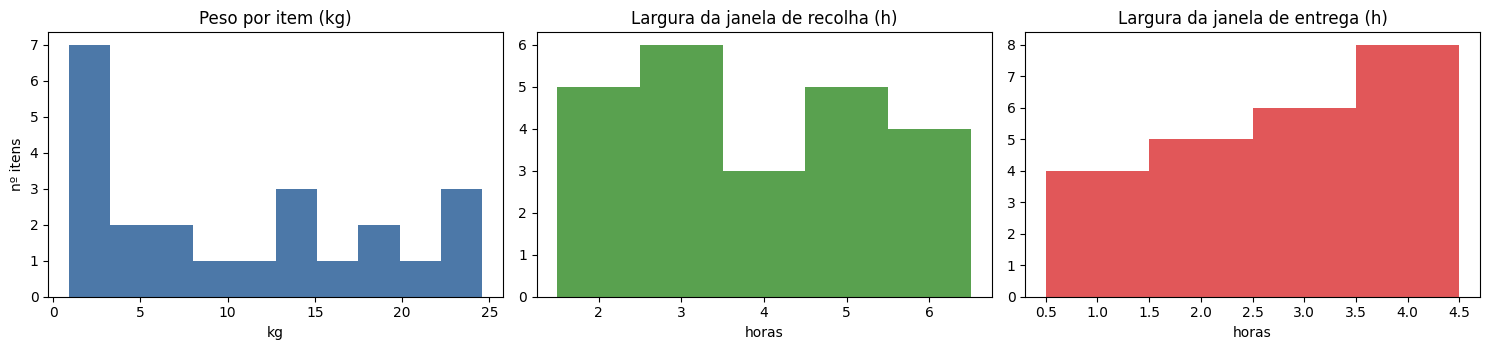

Janelas de recolha: 2-6 h | janelas de entrega: 1-4 h

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(it.weight_kg, bins=10, color="#4c78a8"); ax[0].set(title="Peso por pedido (kg)", xlabel="kg", ylabel="nº pedidos")
ax[1].hist(it.avail_h, bins=[1.5, 2.5, 3.5, 4.5, 5.5, 6.5], color="#59a14f"); ax[1].set(title="Largura da janela de recolha (h)", xlabel="horas")
ax[2].hist(it.deliv_h, bins=[0.5, 1.5, 2.5, 3.5, 4.5], color="#e15759"); ax[2].set(title="Largura da janela de entrega (h)", xlabel="horas")
plt.tight_layout(); plt.show()
print(f"Janelas de recolha: {it.avail_h.min():.0f}-{it.avail_h.max():.0f} h | janelas de entrega: {it.deliv_h.min():.0f}-{it.deliv_h.max():.0f} h")

<h2>3. Coerência das janelas de tempo</h2>

In [6]:
t = pd.DataFrame({
    "recolha_start < recolha_end": (it.availability_start < it.availability_end).all(),
    "entrega_start < entrega_end": (it.delivery_start < it.delivery_end).all(),
    "entrega_end >= recolha_start (pedido pode existir)": (it.delivery_end >= it.availability_start).all(),
    "entrega_start >= recolha_start": (it.delivery_start >= it.availability_start).all()}, index=["todos os pedidos?"]).T
display(t)
late_order = (it.order_datetime > it.availability_start).mean()
print(f"order_datetime posterior ao início da janela de recolha em {late_order:.0%} dos pedidos -> a data da encomenda NÃO é usada como restrição.")
print("Datas de entrega distintas:", it.delivery_start.dt.date.nunique(), "| de", it.delivery_start.min().date(), "a", it.delivery_end.max().date())

,todos os pedidos?
recolha_start < recolha_end,True
entrega_start < entrega_end,True
entrega_end >= recolha_start (pedido pode existir),True
entrega_start >= recolha_start,True


order_datetime posterior ao início da janela de recolha em 57% dos pedidos -> a data da encomenda NÃO é usada como restrição.
Datas de entrega distintas: 13 | de 2026-10-07 a 2026-10-21

<p>As janelas são válidas individualmente. A <code>order_datetime</code> é, na maioria dos pedidos, posterior às janelas (o dataset é sintético), por isso é tratada como informação descritiva e não como restrição. Os pedidos distribuem-se por <b>13 dias diferentes</b>: pedidos de dias distintos são quase independentes, o que ajuda a perceber a dificuldade do problema (secção 7).</p>

<h2>4. Pesos e capacidade da frota</h2>

Carga total: 249.0 kg | capacidade da frota: 2454.5 kg (10.1%) | veículo mais pequeno: 1009.8 kg (24.7%)
Pedido mais pesado: 24.6 kg | encomenda mais pesada: 49.9 kg
Peso máximo a entregar num único dia: 56.7 kg

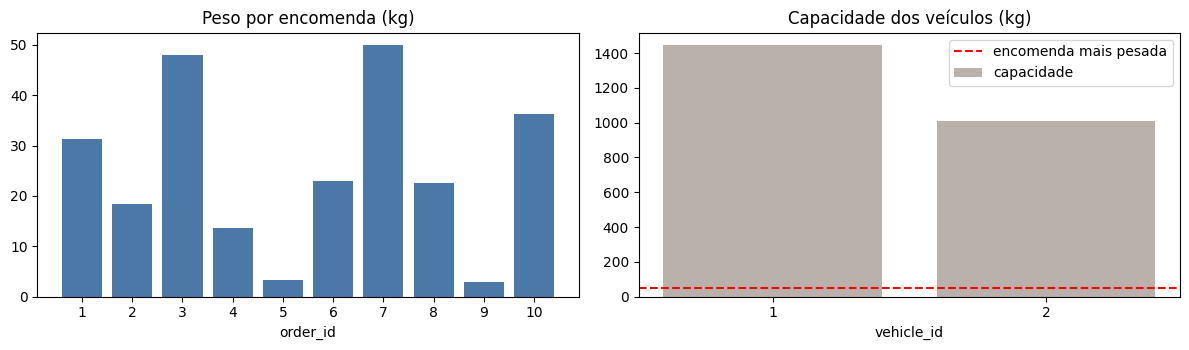

In [7]:
veh = df["vehicles"]
tot = it.weight_kg.sum()
print(f"Carga total: {tot:.1f} kg | capacidade da frota: {veh.capacity_kg.sum():.1f} kg ({tot / veh.capacity_kg.sum():.1%}) | veículo mais pequeno: {veh.capacity_kg.min():.1f} kg ({tot / veh.capacity_kg.min():.1%})")
print(f"Pedido mais pesado: {it.weight_kg.max():.1f} kg | encomenda mais pesada: {it.groupby('order_id').weight_kg.sum().max():.1f} kg")
# Carga máxima possível em simultâneo: dia com mais peso entre recolha e entrega (limite superior)
day = it.groupby(it.delivery_start.dt.date).weight_kg.sum()
print(f"Peso máximo a entregar num único dia: {day.max():.1f} kg")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
w = it.groupby("order_id").weight_kg.sum(); ax[0].bar(w.index.astype(str), w.values, color="#4c78a8"); ax[0].set(title="Peso por encomenda (kg)", xlabel="order_id")
ax[1].bar(veh.vehicle_id.astype(str), veh.capacity_kg, color="#bab0ac", label="capacidade"); ax[1].axhline(w.max(), color="red", ls="--", label="encomenda mais pesada")
ax[1].set(title="Capacidade dos veículos (kg)", xlabel="vehicle_id"); ax[1].legend(); plt.tight_layout(); plt.show()

<p>A carga total (~249 kg) é cerca de 10% da capacidade da frota e ~25% da do veículo mais pequeno; mesmo o dia mais carregado fica muito abaixo de qualquer capacidade. <b>A capacidade não é limitativa</b>; a dificuldade do problema vem das janelas de tempo e da geografia.</p>

<h2>5. Distribuição geográfica</h2>

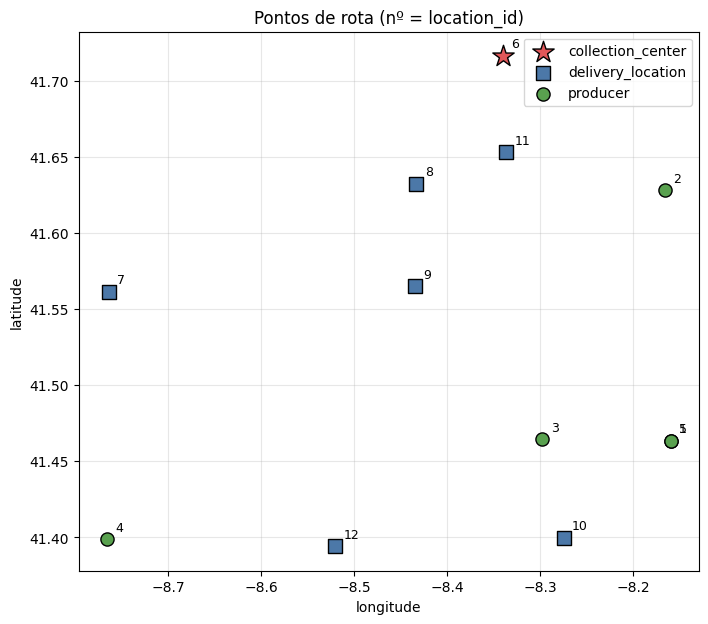

Produtores com coordenadas idênticas: [[1, 'Hortas Valente', 'Fafe'], [5, 'Pomar Antunes', 'Fafe']]

In [8]:
colors = {"producer": "#59a14f", "collection_center": "#e15759", "delivery_location": "#4c78a8"}
markers = {"producer": "o", "collection_center": "*", "delivery_location": "s"}
fig, ax = plt.subplots(figsize=(8, 7))
for tp, g in loc.groupby("location_type"):
    ax.scatter(g.longitude, g.latitude, c=colors[tp], marker=markers[tp], s=260 if tp == "collection_center" else 90, label=tp, edgecolor="k", zorder=3)
    for r in g.itertuples():
        ax.annotate(str(r.location_id), (r.longitude, r.latitude), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set(title="Pontos de rota (nº = location_id)", xlabel="longitude", ylabel="latitude"); ax.legend(); ax.grid(alpha=.3); plt.show()
dup = loc[loc.duplicated(["latitude", "longitude"], keep=False) & (loc.location_type == "producer")]
print("Produtores com coordenadas idênticas:", dup[["location_id", "name", "municipality"]].values.tolist())

<p>Os pontos cobrem uma área de dezenas de km (da Póvoa de Varzim a Fafe). O centro de recolha (Terras de Bouro) fica no extremo norte, a 9–65 km dos restantes pontos (a 65 km da Póvoa de Varzim), o que torna cada passagem obrigatória pelo armazém cara. Os produtores 1 e 5 partilham as mesmas coordenadas (distância 0 entre eles).</p>

<h2>6. Matriz de distâncias</h2>

In [9]:
loc = df["locations"]  
dm = df["distance_matrix"]
n = len(loc)
print(f"Pares: {len(dm)} (esperado {n}x{n-1} = {n*(n-1)}) | pares duplicados: {dm.duplicated(['origin_location_id','destination_location_id']).sum()}")
M = dm.pivot(index="origin_location_id", columns="destination_location_id", values="distance_km")
Tm = dm.pivot(index="origin_location_id", columns="destination_location_id", values="duration_min")
print("Simétrica (distância):", np.allclose(M.fillna(0), M.fillna(0).T), "| simétrica (tempo):", np.allclose(Tm.fillna(0), Tm.fillna(0).T))

# velocidade implícita e fator de estrada face à linha reta (haversine)
def hav(a, b):
    R = 6371.0; p1, p2 = np.radians(a[0]), np.radians(b[0]); dphi = p2 - p1; dl = np.radians(b[1] - a[1])
    return 2 * R * np.arcsin(np.sqrt(np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))
xy = loc.set_index("location_id")[["latitude", "longitude"]].to_dict("index")
dm["straight_km"] = [hav((xy[o]["latitude"], xy[o]["longitude"]), (xy[d]["latitude"], xy[d]["longitude"])) for o, d in zip(dm.origin_location_id, dm.destination_location_id)]
nz = dm[dm.distance_km > 0]
print(f"Velocidade calculada (km/h): min {(nz.distance_km / nz.duration_min * 60).min():.2f} | max {(nz.distance_km / nz.duration_min * 60).max():.2f}")
print(f"Fator de estrada (distance_km / linha reta): min {(nz.distance_km / nz.straight_km).min():.3f} | max {(nz.distance_km / nz.straight_km).max():.3f}")
print("Pares com distância 0:", dm[dm.distance_km == 0][["origin_location_id", "destination_location_id"]].values.tolist())

# desigualdade triangular
A = M.fillna(0).values; viol = 0
for i in range(n):
    for j in range(n):
        for k in range(n):
            if len({i, j, k}) == 3 and A[i, j] > A[i, k] + A[k, j] + 1e-9: viol += 1
print("Violações da desigualdade triangular:", viol)

Pares: 132 (esperado 12x11 = 132) | pares duplicados: 0
Simétrica (distância): True | simétrica (tempo): True
Velocidade calculada (km/h): min 44.93 | max 45.12
Fator de estrada (distance_km / linha reta): min 1.299 | max 1.300
Pares com distância 0: [[1, 5], [5, 1]]
Violações da desigualdade triangular: 0

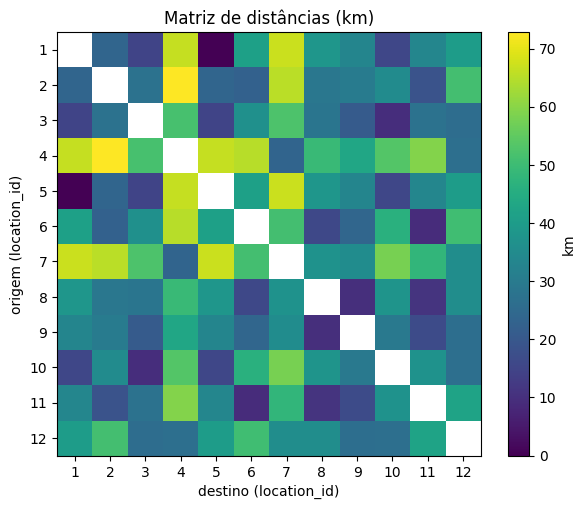

Centro (6) -> restantes pontos (km): {1: 41.4, 2: 22.7, 3: 36.7, 4: 65.0, 5: 41.4, 7: 50.9, 8: 15.7, 9: 24.1, 10: 46.3, 11: 9.1, 12: 50.4}

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(M.values, cmap="viridis"); plt.colorbar(im, label="km")
ax.set_xticks(range(n), M.columns); ax.set_yticks(range(n), M.index); ax.set(title="Matriz de distâncias (km)", xlabel="destino (location_id)", ylabel="origem (location_id)")
plt.show()
print("Centro (6) -> restantes pontos (km):", M.loc[6].dropna().round(1).to_dict())

<p>A matriz é completa e simétrica, com fator de estrada constante de <b>1.3</b> sobre a linha reta e velocidade constante de <b>45 km/h</b>. Como respeita a desigualdade triangular, a distância é um bom guia para heurísticas <b>admissíveis</b> no A* (usadas no <code>Proj01</code>). Os veículos indicam 57.8 e 59.5 km/h, mas usa-se a matriz (45 km/h) para os tempos de viagem.</p>

<h2>7. Viabilidade temporal de cada pedido</h2>

Pedidos viáveis: 22 de 23

,order_item_id,order_id,p,d,availability_start,delivery_start,delivery_end,travel_min,slack_min
7,8,3,4,10,2026-10-12 12:45:00,2026-10-12 13:45:00,2026-10-12 14:45:00,148.4,-28.4


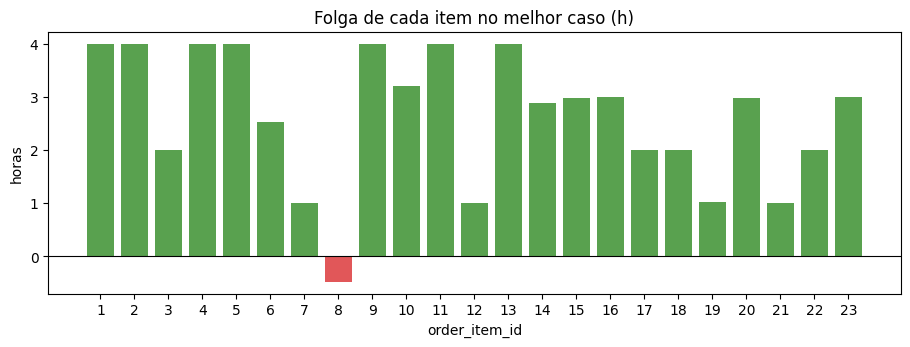

In [11]:
# Melhor caso de cada pedido: recolha no início da janela, produtor -> centro -> cliente, sem espera no armazém
loc_p = loc[loc.location_type == "producer"].set_index("ref_id").location_id
loc_d = loc[loc.location_type == "delivery_location"].set_index("ref_id").location_id
CENTER = int(loc[loc.location_type == "collection_center"].location_id.iloc[0])
D = dm.set_index(["origin_location_id", "destination_location_id"]).duration_min
it["p"], it["d"] = it.producer_id.map(loc_p), it.delivery_location_id.map(loc_d)
it["travel_min"] = [D[(p, CENTER)] + D[(CENTER, d)] for p, d in zip(it.p, it.d)]
it["earliest_delivery"] = [max(a + pd.Timedelta(minutes=m), s) for a, m, s in zip(it.availability_start, it.travel_min, it.delivery_start)]
it["slack_min"] = (it.delivery_end - it.earliest_delivery).dt.total_seconds() / 60
bad = it[it.slack_min < 0]
print(f"Pedidos viáveis: {(it.slack_min >= 0).sum()} de {len(it)}")
display(bad[["order_item_id", "order_id", "p", "d", "availability_start", "delivery_start", "delivery_end", "travel_min", "slack_min"]])
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(it.order_item_id.astype(str), it.slack_min / 60, color=np.where(it.slack_min < 0, "#e15759", "#59a14f"))
ax.axhline(0, color="k", lw=.8); ax.set(title="Folga de cada pedido no melhor caso (h)", xlabel="order_item_id", ylabel="horas"); plt.show()

<p><b>22 dos 23 pedidos são viáveis.</b> O pedido 8 (encomenda 3: Alface da Póvoa de Varzim → Vizela) falha por ~28 min mesmo no melhor caso (recolha logo no início da janela, sem esperas), por isso é impossível de servir dentro da janela de entrega e será entregue fora da mesma, com um atraso mínimo de ~28 min.</p>

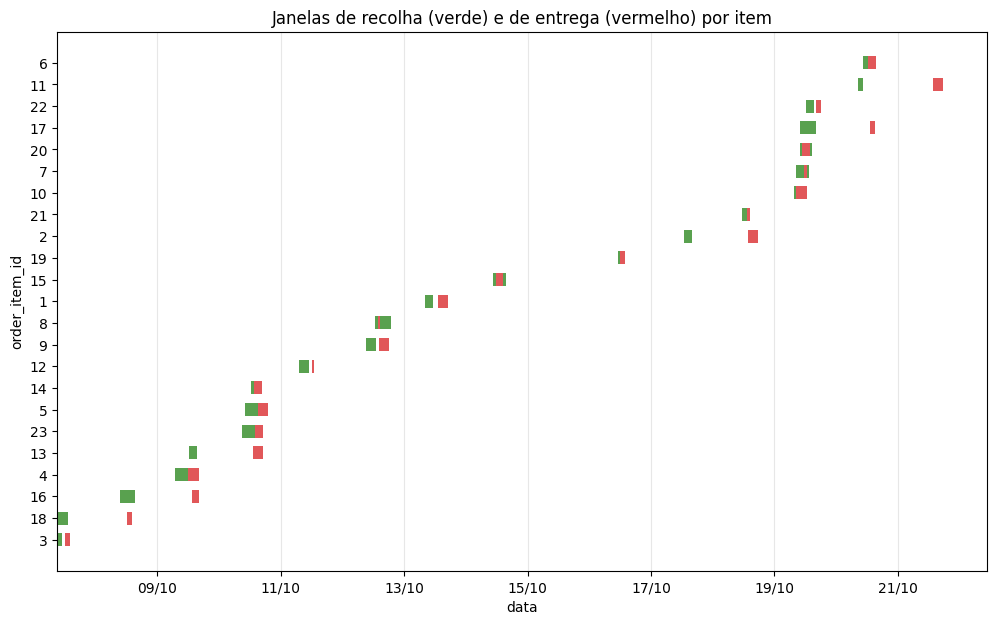

8 grupos temporais independentes: [[3, 18, 16, 4, 13, 23, 5, 14], [12], [9, 8], [1], [15], [19], [2, 21], [10, 7, 20, 17, 22, 11, 6]]

In [12]:
# Linha do tempo das janelas (cada pedido: recolha a verde, entrega a vermelho)
s = it.sort_values("availability_start").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 7))
for i, r in s.iterrows():
    ax.barh(i, mdates.date2num(r.availability_end) - mdates.date2num(r.availability_start), left=mdates.date2num(r.availability_start), color="#59a14f", height=.6)
    ax.barh(i, mdates.date2num(r.delivery_end) - mdates.date2num(r.delivery_start), left=mdates.date2num(r.delivery_start), color="#e15759", height=.6)
ax.set_yticks(range(len(s)), s.order_item_id); ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set(title="Janelas de recolha (verde) e de entrega (vermelho) por pedido", xlabel="data", ylabel="order_item_id"); ax.grid(axis="x", alpha=.3); plt.show()

# Grupos de pedidos cujas janelas [recolha_início, entrega_fim] se sobrepõem
groups, cur, end = [], [], None
for r in s.itertuples():
    if cur and r.availability_start > end: groups.append(cur); cur = []
    cur.append(r.order_item_id); end = max(end, r.delivery_end) if len(cur) > 1 else r.delivery_end
groups.append(cur)
print(len(groups), "grupos temporais independentes:", groups)

<p>Há <b>8 grupos temporais</b> cujas janelas não se sobrepõem entre si: o maior tem 8 pedidos e outro tem 7, e vários têm apenas 1 pedido. Isto explica porque o problema fica difícil de resolver exatamente: dentro de cada grupo há várias ordens possíveis e dois veículos a partilhar o armazém.</p>

<h2>8. Conclusões do EDA</h2>
<ul>
    <li><b>Integridade:</b> dados consistentes, sem valores em falta, duplicados ou referências inválidas.</li>
    <li><b>Janelas de tempo:</b> todas válidas. 22 de 23 pedidos são viáveis (produtor → centro → cliente); o pedido 8 falha por ~28 min mesmo no melhor caso e será entregue fora da janela (atraso mínimo de ~28 min). As janelas de entrega (1–4 h) são a restrição mais apertada; as de recolha têm 2–6 h.</li>
    <li><b>Capacidade:</b> não é limitativa (~249 kg face a 2454.5 kg de frota).</li>
    <li><b>Matriz de distâncias:</b> completa, simétrica, linha reta × 1.3 e 45 km/h; respeita a desigualdade triangular.</li>
    <li><b>Pontos a tratar no modelo:</b> <code>order_datetime</code> não é usado como restrição; os veículos indicam ~58–60 km/h mas usa-se a matriz (45 km/h); os produtores 1 e 5 partilham coordenadas; o centro de recolha fica excêntrico, pelo que cada passagem pelo armazém é cara.</li>
</ul>